<a href="https://colab.research.google.com/github/yuhui-0611/ESAA/blob/main/Bank_Marketing_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 데이터 불러오는 파트

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

train_url = '/content/drive/MyDrive/ESAA/해커톤/Data/train.csv'
test_url = '/content/drive/MyDrive/ESAA/해커톤/Data/test.csv'
sub_url = '/content/drive/MyDrive/ESAA/해커톤/Data/sample_submission.csv'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans

In [ ]:
train = pd.read_csv(train_url)
test = pd.read_csv(test_url)

In [ ]:
import pandas as pd
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 45 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ClientID                  70000 non-null  int64  
 1   Age                       70000 non-null  int64  
 2   Gender                    70000 non-null  object 
 3   MaritalStatus             70000 non-null  object 
 4   EducationLevel            70000 non-null  object 
 5   EmploymentStatus          70000 non-null  object 
 6   JobTitle                  70000 non-null  object 
 7   Region                    70000 non-null  object 
 8   SalaryCategory            70000 non-null  object 
 9   CustomerSegment           70000 non-null  object 
 10  AnnualIncome              70000 non-null  float64
 11  NetWorth                  70000 non-null  float64
 12  CreditScore               69510 non-null  float64
 13  CreditLimit               70000 non-null  float64
 14  RiskRa

In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 44 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ClientID                  30000 non-null  int64  
 1   Age                       30000 non-null  int64  
 2   Gender                    30000 non-null  object 
 3   MaritalStatus             30000 non-null  object 
 4   EducationLevel            30000 non-null  object 
 5   EmploymentStatus          30000 non-null  object 
 6   JobTitle                  30000 non-null  object 
 7   Region                    30000 non-null  object 
 8   SalaryCategory            30000 non-null  object 
 9   CustomerSegment           30000 non-null  object 
 10  AnnualIncome              30000 non-null  float64
 11  NetWorth                  30000 non-null  float64
 12  CreditScore               29803 non-null  float64
 13  CreditLimit               30000 non-null  float64
 14  RiskRa

# 전처리

In [ ]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def my_imputation(df, k=10):
    # 데이터 복사
    x = df.copy()

    # 1. central_value 함수 정의 (R의 로직 그대로)
    def get_central_value(series):
        if pd.api.types.is_numeric_dtype(series):
            return series.median()
        else:
            # 최빈값(Mode) 추출
            return series.mode().iloc[0] if not series.mode().empty else np.nan

    # 2. 거리 계산을 위한 전처리 (수치형/범주형 대응)
    # 범주형이 포함된 경우를 위해 더미화(One-hot)를 임시로 사용하여 거리 계산
    x_dummy = pd.get_dummies(x, drop_first=True)

    # 거리 계산기 (NearestNeighbors)
    # R의 daisy(stand=T)처럼 스케일을 맞추기 위해 표준화는 생략했으나 필요시 추가 가능
    nn = NearestNeighbors(n_neighbors=k+1)
    nn.fit(x_dummy.fillna(0)) # 거리 계산용 임시 채우기

    # 3. 결측치가 있는 행(Row) 탐색
    missing_rows = x.index[x.isnull().any(axis=1)]

    for r_idx in missing_rows:
        # 현재 행의 데이터 (Series 형태)
        target_row = x.iloc[r_idx]

        # 결측치가 있는 칼럼들 찾기
        missing_cols = target_row.index[target_row.isnull()]

        # 해당 행과 가장 가까운 이웃 k개 찾기 (자기 자신 제외를 위해 1:)
        dist, indices = nn.kneighbors(x_dummy.iloc[[r_idx]].fillna(0))
        neighbor_indices = indices[0][1:]

        # 이웃들의 데이터를 가져와서 결측치 채우기
        neighbors_data = x.iloc[neighbor_indices]

        for col in missing_cols:
            x.iloc[r_idx, x.columns.get_loc(col)] = get_central_value(neighbors_data[col])

    return x

# 사용 예시:
# DF_imputed = my_imputation(DF, k=5)

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1) train/test 둘 다에 존재하는 수치형 컬럼만 자동 선택
numeric_features = (
    train.select_dtypes(include=[np.number]).columns
    .intersection(test.select_dtypes(include=[np.number]).columns)
)

# (선택) 타겟이나 ID가 있으면 제거
numeric_features = numeric_features.drop(['target', 'ID'], errors='ignore')

# 2) 스케일러
scaler = StandardScaler()

# 3) train: fit + transform
train_scaled = train.copy()
train_scaled[numeric_features] = scaler.fit_transform(
    train[numeric_features].fillna(train[numeric_features].median())
)

# 4) test: transform만 (median도 train 기준)
test_scaled = test.copy()
test_scaled[numeric_features] = scaler.transform(
    test[numeric_features].fillna(train[numeric_features].median())
)

In [ ]:
train_imp = my_imputation(train, k=5)

In [ ]:
print(train.isna().sum().sum())
print(train_imp.isna().sum().sum())

1868
0


In [ ]:
test_imp = my_imputation(test, k=5)

In [ ]:
print(test.isna().sum().sum())
print(test_imp.isna().sum().sum())

810
0


In [ ]:
## PCA용 데이터 카피

train_df = train_imp.copy()
test_df = test_imp.copy()

## 이우림1~9 전처리

In [ ]:
from sklearn.preprocessing import LabelEncoder
# -----------------------------
# 0) ID 드랍
# -----------------------------
if 'ClientID' in train_imp.columns:
    train_imp.drop(columns=['ClientID'], inplace=True)
if 'ClientID' in test_imp.columns:
    test_imp.drop(columns=['ClientID'], inplace=True)

# -----------------------------
# 1) JobTitle 정규화 + Region 이상값 처리
# -----------------------------
for d in [train_imp, test_imp]:
    # JobTitle_clean
    d['JobTitle_clean'] = (
        d['JobTitle']
        .astype(str)
        .str.lower()
        .str.strip()
    )

    # Region_clean
    fake_regions = ['Mars', 'Atlantis', 'Area-51']
    d['Region_clean'] = d['Region'].replace(fake_regions, 'UnknownRegion')

# 원본 컬럼 제거
train_imp.drop(columns=['JobTitle', 'Region'], inplace=True)
test_imp.drop(columns=['JobTitle', 'Region'], inplace=True)

# -----------------------------
# 2) 라벨 인코딩 (fit은 train_imp만)
# -----------------------------
gender_map = {
    'Male': 0,
    'Female': 1
}

education_map = {
    'Unknown': 0,
    'Primary': 1,
    'Secondary': 2,
    'Tertiary': 3
}

salary_map = {
    'Low': 0,
    'Mid': 1,
    'UpperMid': 2,
    'High': 3
}

segment_map = {
    'Mass': 0,
    'Standard': 1,
    'Premium': 2,
    'Private': 3
}
for d in [train_imp, test_imp]:
    d['Gender'] = d['Gender'].map(gender_map)
    d['EducationLevel'] = d['EducationLevel'].map(education_map)
    d['SalaryCategory'] = d['SalaryCategory'].map(salary_map)
    d['CustomerSegment'] = d['CustomerSegment'].map(segment_map)


# -----------------------------
# 3) 원핫 인코딩 (for문, train 기준 컬럼 맞추기)
# -----------------------------
onehot_cols = ['MaritalStatus', 'EmploymentStatus', 'JobTitle_clean', 'Region_clean']

for col in onehot_cols:
    train_dum = pd.get_dummies(train_imp[col].astype(str), prefix=col)
    test_dum  = pd.get_dummies(test_imp[col].astype(str),  prefix=col)

    # train 기준으로 컬럼 맞추기
    train_dum, test_dum = train_dum.align(
        test_dum,
        join='left',
        axis=1,
        fill_value=0
    )

    train_imp.drop(columns=[col], inplace=True)
    test_imp.drop(columns=[col], inplace=True)

    train_imp = pd.concat([train_imp, train_dum], axis=1)
    test_imp  = pd.concat([test_imp,  test_dum],  axis=1)

## 손현경 파트 전처리

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

train_final = train_imp.copy()
test_final = test_imp.copy()


In [ ]:
# --- [A. 범주형 변수 전처리] ---

# 1-1. 원-핫 인코딩: ChannelPreference, LastContactChannel, LastContactDay
oh_cols = ['ChannelPreference', 'LastContactChannel', 'LastContactDay']
train_final = pd.get_dummies(train_final, columns=oh_cols)
test_final = pd.get_dummies(test_final, columns=oh_cols)

train_final, test_final = train_final.align(test_final, join='left', axis=1, fill_value=0)


In [ ]:
# 1-2. 라벨 인코딩
le_month = LabelEncoder()
train_final['LastContactMonth'] = le_month.fit_transform(train_final['LastContactMonth'].astype(str))
# Train에 없는 값이 Test에 있을 경우를 대비한 매핑
test_final['LastContactMonth'] = test_final['LastContactMonth'].astype(str).map(
    lambda s: le_month.transform([s])[0] if s in le_month.classes_ else -1
)

# 1-3. 수동 매핑:
outcome_map = {'Failure': -1, 'Nonexistent': 0, 'Success': 1}
train_final['PrevCampaignOutcome'] = train_final['PrevCampaignOutcome'].map(outcome_map)
test_final['PrevCampaignOutcome'] = test_final['PrevCampaignOutcome'].map(outcome_map)



In [ ]:
# --- [B. 수치형 변수 전처리] ---

# 2-1. 로그 변환
log_cols = ['LastContactDuration', 'NumPrevCampaignContacts', 'DaysSinceLastContact']
for col in log_cols:
    train_final[col] = np.log1p(train_final[col])
    test_final[col] = np.log1p(test_final[col])

# 2-2. 바이너리 변환
train_final['PreviousYearDeposit'] = (train_final['PreviousYearDeposit'] > 0).astype(int)
test_final['PreviousYearDeposit'] = (test_final['PreviousYearDeposit'] > 0).astype(int)



/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
processed_cols = [
    'LastContactMonth', 'PrevCampaignOutcome', 'LastContactDuration',
    'NumPrevCampaignContacts', 'DaysSinceLastContact', 'PreviousYearDeposit'
]

# 2. 기존 데이터프레임의 해당 칼럼 업데이트
for col in processed_cols:
    train_imp[col] = train_final[col]
    test_imp[col] = test_final[col]

# 3. 신규 생성된 원-핫 인코딩 칼럼들을 옆에 붙이기
new_oh_cols = [col for col in train_final.columns if col not in train_imp.columns]
train_imp = pd.concat([train_imp, train_final[new_oh_cols]], axis=1)
test_imp = pd.concat([test_imp, test_final[new_oh_cols]], axis=1)

# 4. 원본 문자열 칼럼(원핫 전) 삭제
old_cols = ['ChannelPreference', 'LastContactChannel', 'LastContactDay']
train_imp.drop(columns=old_cols, inplace=True, errors='ignore')
test_imp.drop(columns=old_cols, inplace=True, errors='ignore')

## 이서현 전처리

In [ ]:
train_imp['log_AnnualIncome'] = np.log1p(train_imp['AnnualIncome'])
test_imp['log_AnnualIncome']  = np.log1p(test_imp['AnnualIncome'])

train_imp['log_NetWorth'] = np.log1p(train_imp['NetWorth'])
test_imp['log_NetWorth']  = np.log1p(test_imp['NetWorth'])

train_imp['log_AccountBalance'] = np.log1p(train_imp['AccountBalance'])
test_imp['log_AccountBalance']  = np.log1p(test_imp['AccountBalance'])

train_imp['log_InvestmentPortfolioValue'] = np.log1p(train_imp['InvestmentPortfolioValue'])
test_imp['log_InvestmentPortfolioValue']  = np.log1p(test_imp['InvestmentPortfolioValue'])

train_imp['log_CreditLimit'] = np.log1p(train_imp['CreditLimit'])
test_imp['log_CreditLimit']  = np.log1p(test_imp['CreditLimit'])

In [ ]:
risk_map = {
    'Low': 1,
    'Medium': 2,
    'High': 3
}

train_imp['RiskRating_num'] = train['RiskRating'].map(risk_map)
test_imp['RiskRating_num']  = test['RiskRating'].map(risk_map)

In [ ]:
train_imp[['RiskRating', 'RiskRating_num']].head()

,RiskRating,RiskRating_num
0,Medium,2
1,Medium,2
2,High,3
3,Medium,2
4,High,3


In [ ]:
sorted(train_imp['RiskRating_num'].dropna().unique())

[np.int64(1), np.int64(2), np.int64(3)]

- NumBankProducts 구간화

In [ ]:
bins = [0, 1, 2, 3, 4, 5, np.inf]
labels = ['1', '2', '3', '4', '5', '6+']

train_imp['NumBankProducts_group'] = pd.cut(
    train_imp['NumBankProducts'],
    bins=bins,
    labels=labels
)

test_imp['NumBankProducts_group'] = pd.cut(
    test_imp['NumBankProducts'],
    bins=bins,
    labels=labels
)

In [ ]:
train_imp['NumBankProducts_group'].value_counts().sort_index()

,count
NumBankProducts_group,
1,5202
2,16377
3,21430
4,16272
5,7867
6+,2852


- 그대로 사용 : CreditScore, AccountLengthYears, TenureWithBank

편한비 19-29 전처리

In [ ]:
# 1. 0/1 변환 (Yes/No -> 1/0)
# 보유 상품 여부를 숫자로 바꿉니다.
binary_cols = ['HasCreditCard', 'HasMortgage', 'HasPersonalLoan', 'HasLifeInsurance', 'HasMutualFunds']
for col in binary_cols:
    train_imp[col] = train_imp[col].map({'Yes': 1, 'No': 0})
    test_imp[col]= test_imp[col].map({'Yes': 1, 'No': 0})

# 2. 연속형 변수 로그 변환 (Log Transformation)
# np.log1p를 사용하여 왜도(치우침)를 잡습니다.
continuous_cols = [
    'InvestmentPortfolioValue', 'TotalTransactions', 'AvgTransactionValue',
    'NumOnlineTransactions', 'NumMobileAppLogins'
]

for col in continuous_cols:
    # 기존 변수는 유지하고 'Log_'가 붙은 새 컬럼을 생성합니다.
    train_imp[f'Log_{col}'] = np.log1p(train_imp[col].clip(lower=0))
    test_imp[f'Log_{col}'] = np.log1p(test_imp[col].clip(lower=0))


# 3. 변수 구간화 (BranchVisit_Group)
def bin_branch_visit(x):
    if x == 0: return 0
    elif x <= 2: return 1
    elif x <= 5: return 2
    else: return 3

train_imp['BranchVisit_Group'] = train_imp['BranchVisitFrequency'].apply(bin_branch_visit)
test_imp['BranchVisit_Group'] = test_imp['BranchVisitFrequency'].apply(bin_branch_visit)

# 4. [추가 전처리] 이상치 클리핑 (Outlier Clipping)
# 거래 횟수(TotalTransactions)가 비정상적으로 높은 경우, 모델이 헷갈리지 않게 상위 1% 값으로 고정합니다.
upper_limit = train_imp['TotalTransactions'].quantile(0.99)
train_imp['TotalTransactions_Clipped'] = train_imp['TotalTransactions'].clip(upper=upper_limit)
train_imp['Log_TotalTransactions_Clipped'] = np.log1p(train_imp['TotalTransactions_Clipped'])

test_imp['TotalTransactions_Clipped'] = test_imp['TotalTransactions'].clip(upper=upper_limit)
test_imp['Log_TotalTransactions_Clipped'] = np.log1p(test_imp['TotalTransactions_Clipped'])



In [ ]:
train_imp.drop('RiskRating',axis=1,inplace=True)
test_imp.drop('RiskRating',axis=1,inplace=True)

num_products_map = {
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '6+': 6
}

for d in [train_imp, test_imp]:
    d['NumBankProducts_group'] = (
        d['NumBankProducts_group']
        .astype(str)
        .map(num_products_map)
        .astype(int)
    )

In [ ]:
train_imp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 87 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             70000 non-null  int64  
 1   Gender                          70000 non-null  int64  
 2   EducationLevel                  70000 non-null  int64  
 3   SalaryCategory                  70000 non-null  int64  
 4   CustomerSegment                 70000 non-null  int64  
 5   AnnualIncome                    70000 non-null  float64
 6   NetWorth                        70000 non-null  float64
 7   CreditScore                     70000 non-null  float64
 8   CreditLimit                     70000 non-null  float64
 9   AccountLengthYears              70000 non-null  float64
 10  TenureWithBank                  70000 non-null  float64
 11  AccountBalance                  70000 non-null  float64
 12  NumBankProducts                 

In [ ]:
test_imp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 86 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             30000 non-null  int64  
 1   Gender                          30000 non-null  int64  
 2   EducationLevel                  30000 non-null  int64  
 3   SalaryCategory                  30000 non-null  int64  
 4   CustomerSegment                 30000 non-null  int64  
 5   AnnualIncome                    30000 non-null  float64
 6   NetWorth                        30000 non-null  float64
 7   CreditScore                     30000 non-null  float64
 8   CreditLimit                     30000 non-null  float64
 9   AccountLengthYears              30000 non-null  float64
 10  TenureWithBank                  30000 non-null  float64
 11  AccountBalance                  30000 non-null  float64
 12  NumBankProducts                 

# PCA + 클러스터링

In [ ]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt



In [ ]:
target_cols = [
    'Age', 'EducationLevel', 'CustomerSegment', 'SalaryCategory', 'AnnualIncome',
    'CreditScore', 'TenureWithBank', 'TotalTransactions', 'PrevCampaignOutcome',
    'MarketingScore', 'LastContactDuration', 'HasMutualFunds',
    'WebsiteActivityScore', 'MaritalStatus', 'NetWorth', 'ResponsePropensity'
]
train_df = train_df[target_cols].copy()
test_df = test_df[target_cols].copy()

In [ ]:
# 2. 범주형 변수 처리
# (1) PrevCampaignOutcome: 수동 매핑

outcome_map = {'Success': 1, 'Failure': -1, 'Nonexistent': 0}
train_df['PrevCampaignOutcome'] = train_df['PrevCampaignOutcome'].map(outcome_map)
test_df['PrevCampaignOutcome'] = test_df['PrevCampaignOutcome'].map(outcome_map)


In [ ]:
# (2) EducationLevel, SalaryCategory: 라벨 인코딩
le = LabelEncoder()
for col in ['EducationLevel', 'SalaryCategory']:
    train_df[col] = le.fit_transform(train_df[col].astype(str))
    test_df[col] = test_df[col].astype(str).map(lambda s: le.transform([s])[0] if s in le.classes_ else -1)


In [ ]:
# (3) HasMutualFunds: 바이너리 (Yes/No 등을 1/0으로)
le_funds = LabelEncoder()
train_df['HasMutualFunds'] = le_funds.fit_transform(train_df['HasMutualFunds'].astype(str))
test_df['HasMutualFunds'] = le_funds.transform(test_df['HasMutualFunds'].astype(str))

# (4) CustomerSegment, MaritalStatus: 원-핫 인코딩
train_df = pd.get_dummies(train_df, columns=['CustomerSegment', 'MaritalStatus'])
test_df = pd.get_dummies(test_df, columns=['CustomerSegment', 'MaritalStatus'])


In [ ]:
train_df, test_df = train_df.align(test_df, join='left', axis=1, fill_value=0)

In [ ]:
# 3. 연속형 변수 스케일링
numeric_cols = [
    'Age', 'AnnualIncome', 'CreditScore', 'TenureWithBank', 'TotalTransactions',
    'MarketingScore', 'LastContactDuration', 'WebsiteActivityScore', 'NetWorth', 'ResponsePropensity'
]

In [ ]:
scaler = StandardScaler()
train_df[numeric_cols] = scaler.fit_transform(train_df[numeric_cols])
test_df[numeric_cols] = scaler.transform(test_df[numeric_cols])

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(train_df)
test_pca = pca.transform(test_df)

In [ ]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
train_imp['Cluster'] = kmeans_4.fit_predict(X_pca)

test_cluster_labels = kmeans_4.predict(test_pca)
test_imp['Cluster'] = test_cluster_labels

In [ ]:
numeric_cols = ['Age', 'AnnualIncome', 'CreditScore', 'TenureWithBank',
                'TotalTransactions', 'MarketingScore', 'LastContactDuration',
                'WebsiteActivityScore', 'NetWorth', 'ResponsePropensity']

cluster_summary_train = train_imp.groupby('Cluster')[numeric_cols].mean()
cluster_summary_test = test_imp.groupby('Cluster')[numeric_cols].mean()


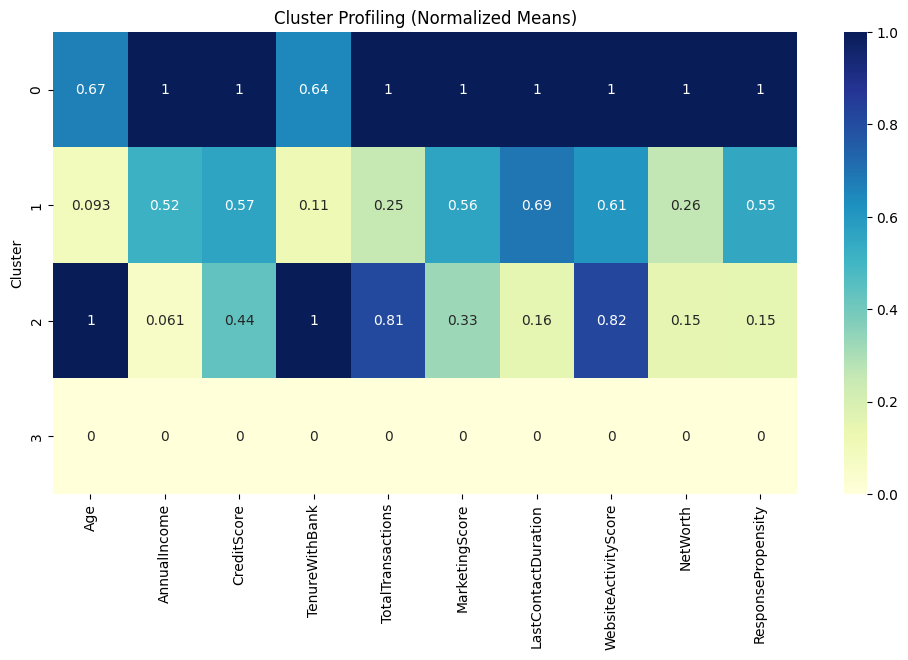

In [ ]:
import seaborn as sns
plt.figure(figsize=(12, 6))

sns.heatmap(cluster_summary_train.apply(lambda x: (x - x.min()) / (x.max() - x.min())),
            annot=True, cmap='YlGnBu')
plt.title('Cluster Profiling (Normalized Means)')
plt.show()

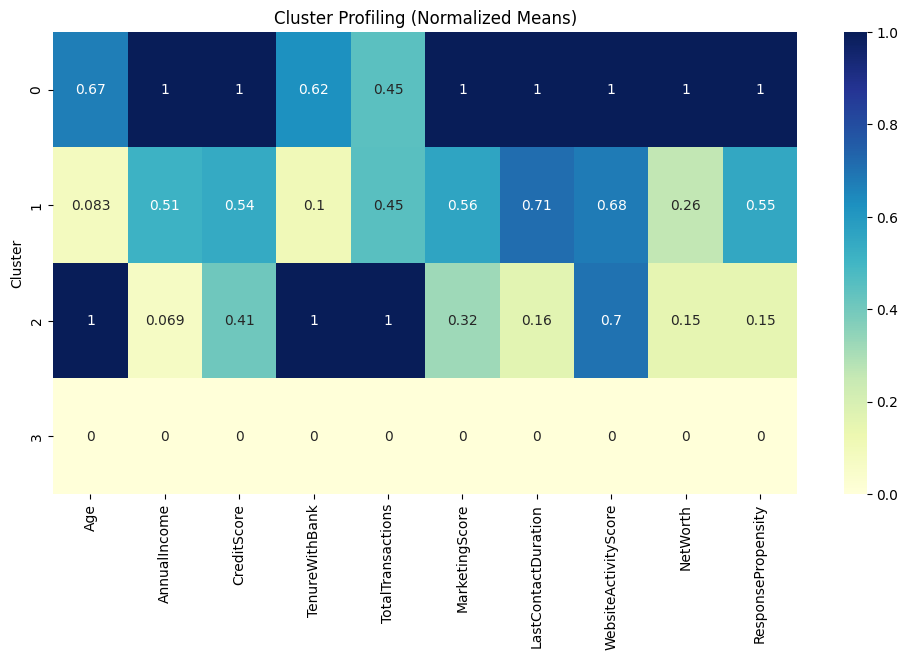

In [ ]:
import seaborn as sns
plt.figure(figsize=(12, 6))

sns.heatmap(cluster_summary_test.apply(lambda x: (x - x.min()) / (x.max() - x.min())),
            annot=True, cmap='YlGnBu')
plt.title('Cluster Profiling (Normalized Means)')
plt.show()

cluster 0 : VIP
  - 연봉, 순자산, 신용 점수 등 거의 모든 금융 지표가 1.0 (최상위) 연령대가 높고 거래 횟수나 마케팅 반응도가 매우 높음 >> 완벽한 고객. 유지가 중요함

cluster 1 : 비활성 / 신규 고객
 - 모든 지표가 0에 수렴함. 가입만 하고 활동이 전혀 없는 고객군

cluster 2 : 충성도 높은 고령 활동가
  - 나이와 은행 근속 연수가 가장 높음. 자산은 적지만 거래 횟수와 웹사이트 활동이 매우 활발함. 오랫동안 은행을 이용한 충성 고객층

cluster 3 : 디지털 잠재 고객
  - 나이가 가장 어리고 근속 연수도 짧지만 연봉과 신용 점수는 정간 이상. 마케팅 점수와 웹사이트 활동 점수가 준수하며 반응 가능성도 높음 >>> 미래의 VIP가 될 가능성이 높은 타겟
  

# 파생변수

In [ ]:
import numpy as np
import pandas as pd

def apply_feature_engineering(df):
    income_median = df['AnnualIncome'].median()
    web_median = df['WebsiteActivityScore'].median()

    # 1. 활동성 및 디지털 지표 (중복 제거 및 통합)
    df['Total_Activity_Score'] = df['TotalTransactions'] + df['NumMobileAppLogins'] + df['BranchVisitFrequency']
    df['Digital_Usage_Ratio'] = (df['NumOnlineTransactions'] + df['NumMobileAppLogins']) / (df['TotalTransactions'] + 1)
    df['Web_Engagement_Index'] = df['WebsiteActivityScore'] / (df['NumMobileAppLogins'] + 1)

    # 2. 경제적 잠재력 (나이/소득/신용 결합)
    # 나이가 적을수록, 연봉과 신용이 높을수록 커지는 지수
    df['Young_High_Credit_Score'] = (df['CreditScore'] * df['AnnualIncome']) / (df['Age'] + 1)
    df['Wealth_Accumulation_Ratio'] = df['NetWorth'] / (df['AnnualIncome'] + 1)
    df['Investment_Focus_Ratio'] = df['InvestmentPortfolioValue'] / (df['NetWorth'] + 1)

    # 3. 은행 관계 및 충성도
    df['Transaction_per_Tenure'] = df['TotalTransactions'] / (df['TenureWithBank'] + 1)
    df['Product_Density'] = df['NumBankProducts'] / (df['TenureWithBank'] + 1)
    df['Activity_per_Asset'] = df['TotalTransactions'] / (df['AccountBalance'] + 1)

    # 4. 마케팅 및 리텐션 위험
    df['Marketing_Efficiency'] = df['MarketingScore'] * df['ResponsePropensity']
    df['Contact_Intensity'] = df['NumContactsInCampaign'] / (df['DaysSinceLastContact'] + 1)
    df['Contact_Gap_Risk'] = df['DaysSinceLastContact'] * (1 - df['CallResponseScore'])

    # 5. 세그먼트 플래그 (Binary)
    df['Is_Digital_VIP_Candidate'] = ((df['AnnualIncome'] > income_median) &
                                      (df['WebsiteActivityScore'] > web_median)).astype(int)
    df['Is_Senior_Loyal'] = ((df['Age'] >= 60) & (df['TenureWithBank'] >= 10)).astype(int)

    # 6. 군집(Cluster) 연계 변수 (Cluster 칼럼이 있을 경우에만 실행)
    if 'Cluster' in df.columns:
        # 군집 1: 비활성/유령 고객 식별
        df['C1_Pure_Dormant'] = ((df['Cluster'] == 1) & (df['Total_Activity_Score'] == 0)).astype(int)
        # 군집 1: 잠재적 전환 자산가
        df['C1_Asset_Holders'] = ((df['Cluster'] == 1) & (df['AccountBalance'] > df['AccountBalance'].median())).astype(int)
        # 군집 3: 디지털 잠재 VIP 타겟 (미래의 VIP)
        df['C3_Future_VIP'] = ((df['Cluster'] == 3) & (df['ResponsePropensity'] > df['ResponsePropensity'].mean())).astype(int)

    return df

# 데이터셋에 적용
train_imp = apply_feature_engineering(train_imp)
test_imp = apply_feature_engineering(test_imp)

In [ ]:
train_imp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Columns: 105 entries, Age to C3_Future_VIP
dtypes: bool(36), float64(38), int32(1), int64(30)
memory usage: 39.0 MB


# 모델링

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix


X = train_imp.drop(columns=["TermDepositSubscribed", "cluster"], errors="ignore")
y = train_imp["TermDepositSubscribed"]


In [ ]:
def make_finite_float64(df: pd.DataFrame) -> pd.DataFrame:
    # object 섞였으면 숫자로 강제(변환 실패는 NaN)
    df = df.apply(pd.to_numeric, errors="coerce")

    # 무한대/너무 큰 값 방지: float64로 고정 후 유한화
    arr = df.to_numpy(dtype=np.float64, copy=True)
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)

    # 최종 유한성 체크
    if not np.isfinite(arr).all():
        raise ValueError("아직도 비유한 값이 남아 있습니다.")

    return pd.DataFrame(arr, columns=df.columns, index=df.index)



In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = make_finite_float64(X_train)
X_valid = make_finite_float64(X_valid)


In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf.fit(X_train, y_train)


KeyboardInterrupt: 

In [ ]:
y_prob = rf.predict_proba(X_valid)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

In [ ]:
f1 = f1_score(y_valid, y_pred)
print("F1-score (threshold=0.5):", f1)

print("\nConfusion Matrix\n", confusion_matrix(y_valid, y_pred))
print("\nClassification Report\n", classification_report(y_valid, y_pred))

In [ ]:
thresholds = np.arange(0.05, 0.96, 0.05)
best_t, best_f1 = 0.5, -1

for t in thresholds:
    pred_t = (y_prob >= t).astype(int)
    f1_t = f1_score(y_valid, pred_t)
    if f1_t > best_f1:
        best_f1, best_t = f1_t, t

print("\nBest threshold:", best_t)
print("Best F1-score:", best_f1)

In [ ]:
!pip -q install optuna


In [ ]:
import numpy as np
import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

param_dist = {
    "n_estimators": randint(100, 501),
    "max_depth": randint(3, 26),
    "min_samples_split": randint(2, 31),
    "min_samples_leaf": randint(1, 21),
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced"]
}

rs = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,             # 30~60이면 보통 충분
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rs.fit(X_train, y_train)
print("Best F1(CV):", rs.best_score_)
print("Best params:", rs.best_params_)

In [ ]:
import lightgbm as lgb
import optuna
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

# ---------------------------------------------------------
# 1. 데이터 준비 및 ClientID 보존
# ---------------------------------------------------------
X = train_imp.drop(['TermDepositSubscribed'], axis=1)
if 'ClientID' in X.columns: X = X.drop(columns=['ClientID'])
y = train_imp['TermDepositSubscribed']

X_test = test_imp.copy()
submission_id = test['ClientID'] # ID 미리 저장
if 'ClientID' in X_test.columns: X_test = X_test.drop(columns=['ClientID'])

# 컬럼 일치 및 수치형 변환
common_cols = X.columns.intersection(X_test.columns)
X, X_test = X[common_cols], X_test[common_cols]
X = X.apply(pd.to_numeric, errors='coerce').fillna(0)
X_test = X_test.apply(pd.to_numeric, errors='coerce').fillna(0)

# ---------------------------------------------------------
# 2. Optuna 목적 함수 정의
# ---------------------------------------------------------
def objective(trial):
    param = {
        'objective': 'binary',
        'verbosity': -1,
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.03),
        'num_leaves': trial.suggest_int('num_leaves', 31, 255),
        'max_depth': trial.suggest_int('max_depth', 7, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 0.9),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 0.9),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.5, 4.0) # 불균형 해소 핵심
    }

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42) # 속도를 위해 3-Fold
    f1_scores = []

    for trn_idx, val_idx in skf.split(X, y):
        X_trn, y_trn = X.iloc[trn_idx], y.iloc[trn_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        model = lgb.LGBMClassifier(**param, n_estimators=1000, random_state=42)
        model.fit(X_trn, y_trn, eval_set=[(X_val, y_val)],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

        # 확률 예측 및 최적 임계값 적용
        probs = model.predict_proba(X_val)[:, 1]

        # 0.1~0.6 사이에서 최적 F1 찾기
        th_scores = [f1_score(y_val, (probs > th).astype(int)) for th in np.arange(0.1, 0.6, 0.05)]
        f1_scores.append(max(th_scores))

    return np.mean(f1_scores)

# ---------------------------------------------------------
# 3. 최적화 실행 (20~30회 정도 권장)
# ---------------------------------------------------------
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30) # 시간 여유에 따라 횟수 조절

print("Best Parameters:", study.best_params)

# ---------------------------------------------------------
# 4. 최적 파라미터로 최종 학습 및 예측
# ---------------------------------------------------------
best_params = study.best_params
best_params['objective'] = 'binary'

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros(len(X))
test_probs = np.zeros(len(X_test))

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_trn, y_trn = X.iloc[trn_idx], y.iloc[trn_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**best_params, n_estimators=3000, random_state=42)
    model.fit(X_trn, y_trn, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)])

    oof_probs[val_idx] = model.predict_proba(X_val)[:, 1]
    test_probs += model.predict_proba(X_test)[:, 1] / 5

# ---------------------------------------------------------
# 5. 최종 임계값 탐색 및 제출 (ClientID 포함)
# ---------------------------------------------------------
best_th = 0.5
max_f1 = 0
for th in np.arange(0.1, 0.7, 0.005):
    score = f1_score(y, (oof_probs > th).astype(int))
    if score > max_f1:
        max_f1 = score
        best_th = th

print(f"\n최종 F1: {max_f1:.4f} (at Threshold {best_th:.4f})")

final_preds = (test_probs > best_th).astype(int)
submission = pd.DataFrame({
    'ClientID': submission_id, # 에러 방지용 보존된 ID
    'TermDepositSubscribed': final_preds
})

submission.to_csv('lgbm_optuna_final.csv', index=False)

XGBoost

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score, classification_report

# ==========================================
# 1. 데이터 최종 정제 및 분리
# ==========================================
# 학습에 제외할 컬럼 (타겟, ID, 중복 처리된 문자열 등)
drop_cols = ['TermDepositSubscribed', 'RiskRating', 'NumBankProducts_group', 'ClientID']

# X, y 분리
X = train_imp.drop(columns=[c for c in drop_cols if c in train_imp.columns])
y = train_imp['TermDepositSubscribed']

def finalize_for_xgb(df):
    # 1) bool 타입을 int로 변환
    df = df.astype({col: 'int' for col in df.select_dtypes('bool').columns})
    # 2) 무한대(inf) 처리: 로그 변환 등으로 발생한 inf를 NaN으로 바꾼 후 중앙값 채우기
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.fillna(df.median())
    # 3) XGBoost 전용 타입 float32 변환
    return df.astype('float32')

X = finalize_for_xgb(X)

# 학습/검증 데이터 분리 (8:2)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


#  XGBoost 모델 설정 및 학습
xgb_single = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.02,
    max_depth=7,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100,
    enable_categorical=True
)

# 학습 실행
xgb_single.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

# ==========================================
# 3. 모델 평가
# ==========================================
val_preds = xgb_single.predict(X_val)
val_probs = xgb_single.predict_proba(X_val)[:, 1]

print("\n" + "="*40)
print(f"최적 반복 횟수(Best Iteration): {xgb_single.best_iteration}")
print(f"검증 데이터 F1 Score: {f1_score(y_val, val_preds):.4f}")
print(f"검증 데이터 AUC Score: {roc_auc_score(y_val, val_probs):.4f}")
print("="*40)
print("\n[상세 분류 보고서]")
print(classification_report(y_val, val_preds))

In [ ]:
from sklearn.metrics import f1_score
import numpy as np

# 1. 검증 데이터 확률 예측
val_probs = xgb_single.predict_proba(X_val)[:, 1]

# 2. 최적의 F1 스코어를 만드는 임계값(Threshold) 찾기
best_f1 = 0
best_th = 0.5

for th in np.arange(0.1, 0.9, 0.01):
    temp_preds = (val_probs > th).astype(int)
    temp_f1 = f1_score(y_val, temp_preds)
    if temp_f1 > best_f1:
        best_f1 = temp_f1
        best_th = th

print(f"최적 임계값: {best_th:.2f}")
print(f"예상 리더보드 F1 스코어: {best_f1:.5f}")

# 3. (참고) 기본값 0.5일 때의 점수와 비교
base_f1 = f1_score(y_val, (val_probs > 0.5).astype(int))
print(f"기본(0.5) F1 스코어: {base_f1:.5f}")

In [ ]:
# 1. 테스트 데이터 전처리 및 확률 예측
X_test_final = finalize_for_xgb(test_imp.drop(columns=[c for c in drop_cols if c in test_imp.columns], errors='ignore'))
test_probs = xgb_single.predict_proba(X_test_final)[:, 1]

# 2. 최적 임계값 적용 (아까 찾은 best_th 사용)
submission = pd.read_csv('/content/drive/MyDrive/ESAA/해커톤/Data/sample_submission.csv')
submission['TermDepositSubscribed'] = (test_probs > best_th).astype(int)

# 3. 파일 저장
submission.to_csv('submission.csv', index=False)

In [ ]:
from catboost import CatBoostClassifier
import numpy as np

target = 'TermDepositSubscribed'

X_train = train_imp.drop(columns=[target])
y_train = train_imp[target]

# class weight 다시 계산
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
ratio = neg / pos

final_model = CatBoostClassifier(
    iterations=1000,              # early stopping 없이 충분히
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=1,
    loss_function='Logloss',
    eval_metric='F1',
    class_weights=[1.0, ratio],
    random_seed=42,
    verbose=200
)

final_model.fit(X_train, y_train)

0:	learn: 0.6108810	total: 85.8ms	remaining: 1m 25s
200:	learn: 0.6414730	total: 17.6s	remaining: 1m 9s
400:	learn: 0.6502213	total: 26.7s	remaining: 39.8s
600:	learn: 0.6650600	total: 34.2s	remaining: 22.7s
800:	learn: 0.6773064	total: 43.2s	remaining: 10.7s
999:	learn: 0.6905637	total: 53.7s	remaining: 0us


In [ ]:
test_proba = final_model.predict_proba(test_imp)[:, 1]
best_threshold = 0.49

test_pred = (test_proba >= best_threshold).astype(int)
submission = pd.read_csv('sample_submission.csv')

submission['TermDepositSubscribed'] = test_pred

submission.to_csv('catboost_single1000_49.csv', index=False)

In [ ]:
import pandas as pd

# ====== 입력 파일 경로 ======
PATH_CAT = "catboost_single1000_49.csv"
PATH_RF  = "submission_rf_hg.csv"
PATH_LGB = "lgbm_optuna_final_hb.csv"
PATH_XGB = "submission_xgb_s.csv"

# ====== 출력 파일 경로 ======
OUT_PATH = "submission_ensemble_weighted1112.csv"

# ====== 가중치 설정 (XGB를 더 높게) ======
W_CAT, W_RF, W_LGB, W_XGB = 1, 1, 1, 2

TARGET_COL = "TermDepositSubscribed"
ID_COL = "ClientID"

def load_and_check(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    # 컬럼 체크
    if ID_COL not in df.columns or TARGET_COL not in df.columns:
        raise ValueError(f"{path} 에 {ID_COL}, {TARGET_COL} 컬럼이 필요합니다. 현재 컬럼: {df.columns.tolist()}")
    # 타입/값 체크(0/1)
    df[TARGET_COL] = df[TARGET_COL].astype(int)
    bad = df[~df[TARGET_COL].isin([0, 1])]
    if len(bad) > 0:
        raise ValueError(f"{path} 에 0/1이 아닌 값이 있습니다. 예시:\n{bad.head()}")
    return df[[ID_COL, TARGET_COL]].copy()

# ====== 로드 ======
cat = load_and_check(PATH_CAT).rename(columns={TARGET_COL: f"{TARGET_COL}_cat"})
rf  = load_and_check(PATH_RF ).rename(columns={TARGET_COL: f"{TARGET_COL}_rf"})
lgb = load_and_check(PATH_LGB).rename(columns={TARGET_COL: f"{TARGET_COL}_lgb"})
xgb = load_and_check(PATH_XGB).rename(columns={TARGET_COL: f"{TARGET_COL}_xgb"})

# ====== 병합(모든 파일에 동일 ClientID 존재한다고 가정) ======
df = cat.merge(rf, on=ID_COL, how="inner")
df = df.merge(lgb, on=ID_COL, how="inner")
df = df.merge(xgb, on=ID_COL, how="inner")

# 혹시 누락되면 알려주기
expected = len(cat)
if len(df) != expected:
    print(f"[WARN] 병합 후 행 수가 줄었습니다: cat={expected}, merged={len(df)} (ClientID 불일치/누락 가능)")

# ====== Weighted Hard Voting ======
score = (
    W_CAT * df[f"{TARGET_COL}_cat"] +
    W_RF  * df[f"{TARGET_COL}_rf"] +
    W_LGB * df[f"{TARGET_COL}_lgb"] +
    W_XGB * df[f"{TARGET_COL}_xgb"]
)
total_w = W_CAT + W_RF + W_LGB + W_XGB

# threshold = total_w/2 (동점은 1로 처리: >=)
df[TARGET_COL] = (score >= (total_w / 2)).astype(int)

# ====== 저장 ======
out = df[[ID_COL, TARGET_COL]].sort_values(ID_COL)
out.to_csv(OUT_PATH, index=False)

print("Saved:", OUT_PATH)
print(out.head())